
# Diagnostiquer les performances d'un modèle en production

**Module : Optimisation des modèles d'apprentissage automatique pour la production**  
**Durée indicative : 1 heure**

## Objectifs pédagogiques

À la fin de cette séquence, vous saurez :
- distinguer latence, temps d'inférence et débit ;
- mesurer le temps d'exécution d'un modèle de manière reproductible ;
- comprendre le rôle du *warm-up* et de la synchronisation GPU ;
- mesurer la mémoire utilisée par un modèle ;
- observer l'influence de la taille des lots (*batch size*) ;
- établir une référence (*baseline*) pour évaluer les optimisations ultérieures.

## Mise en situation

Une application reçoit des images et doit les classifier. Le modèle donne de bons résultats, mais on ne sait pas encore s'il est suffisamment rapide, s'il consomme trop de mémoire ou combien d'images il peut traiter par seconde.

Avant de modifier le modèle, il faut répondre à une question essentielle :

> **Comment savoir objectivement si une optimisation améliore réellement le système ?**

Nous allons charger un modèle de classification d'images préentraîné depuis Hugging Face, puis construire un protocole de mesure. Le modèle choisi est `microsoft/resnet-18`. Vous pourrez ensuite remplacer ce modèle par celui de votre projet.

## 1. Préparer l'environnement

Bibliothèques utilisées : PyTorch pour l'exécution du réseau, Transformers pour le modèle Hugging Face, Pillow pour les images et Matplotlib/Pandas pour les résultats.

Dans un environnement de cours déjà préparé, cette installation peut être ignorée.


In [7]:
%pip install -q torch transformers pillow matplotlib pandas

## 2. Charger un modèle de référence

Nous séparons le prétraitement de l'image du passage dans le réseau (*forward pass*). Cette distinction permet de mesurer le modèle seul, puis la chaîne complète.


In [8]:
import time
import platform
import statistics
import torch
import pandas as pd
import matplotlib.pyplot as plt

from transformers import AutoImageProcessor, AutoModelForImageClassification

MODEL_ID = "microsoft/resnet-18"

processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageClassification.from_pretrained(MODEL_ID)

print("Modèle chargé :", MODEL_ID)
print("PyTorch :", torch.__version__)
print("Python :", platform.python_version())

Loading weights:   0%|          | 0/122 [00:00<?, ?it/s]

Modèle chargé : microsoft/resnet-18
PyTorch : 2.14.1+cpu
Python : 3.13.18


### 2.1 Choisir le matériel d'exécution

Le même modèle peut avoir des performances très différentes sur CPU et GPU. Nous sélectionnons automatiquement un GPU CUDA s'il est disponible.

Un GPU ne garantit pas automatiquement une inférence plus rapide : pour de petits modèles ou de petits lots, les coûts de lancement et de transfert peuvent réduire le bénéfice.


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("Périphérique utilisé :", device)
if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("Aucun GPU CUDA détecté : exécution sur CPU.")

Périphérique utilisé : cpu
Aucun GPU CUDA détecté : exécution sur CPU.


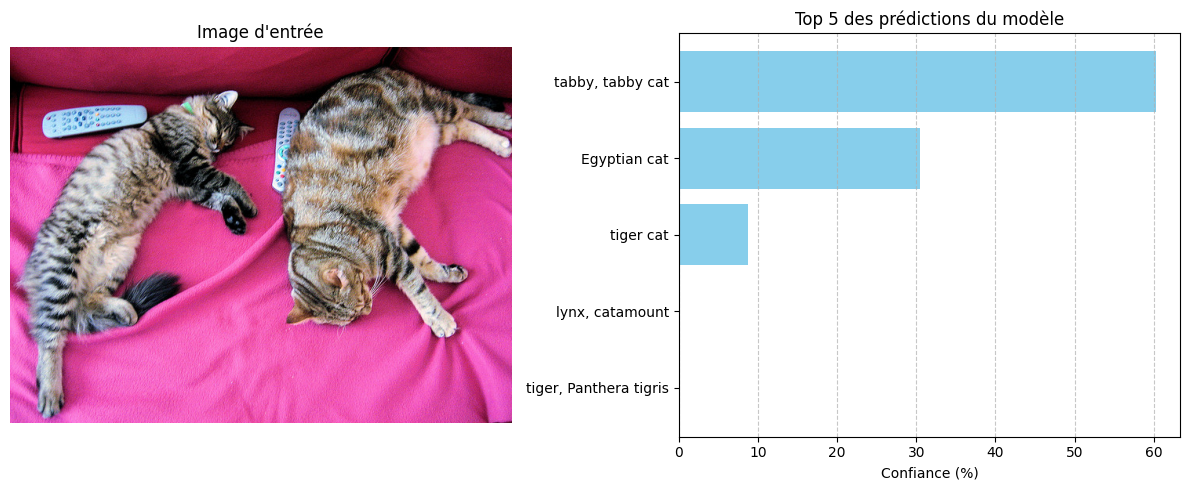

In [10]:
import urllib.request
import ssl
from PIL import Image
import torch
import matplotlib.pyplot as plt

# 1. Télécharger une image d'exemple (un chat) avec contournement SSL si nécessaire
url = "https://images.cocodataset.org/val2017/000000039769.jpg"
image_path = "cat_example.jpg"

# Création d'un contexte SSL non vérifié pour contourner l'erreur de certificat
ssl_context = ssl._create_unverified_context()
with urllib.request.urlopen(url, context=ssl_context) as response, open(image_path, 'wb') as out_file:
    out_file.write(response.read())

image = Image.open(image_path)

# 2. Prétraiter l'image pour le modèle
inputs = processor(images=image, return_tensors="pt").to(device)

# 3. Effectuer la prédiction (inférence)
with torch.no_grad():
    outputs = model(**inputs)
    logits = outputs.logits

# 4. Convertir les logits en probabilités (softmax)
probs = torch.nn.functional.softmax(logits, dim=-1)[0]

# 5. Récupérer les 5 meilleures classes
top5_prob, top5_catid = torch.topk(probs, 5)

# Obtenir les labels textuels correspondant aux IDs
labels = [model.config.id2label[catid.item()] for catid in top5_catid]
probabilities = [prob.item() * 100 for prob in top5_prob]

# 6. Visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Affichage de l'image
axes[0].imshow(image)
axes[0].axis("off")
axes[0].set_title("Image d'entrée")

# Graphique des prédictions
y_pos = range(len(labels))
axes[1].barh(y_pos, probabilities, align="center", color="skyblue")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(labels)
axes[1].invert_yaxis()  # Mettre la meilleure prédiction en haut
axes[1].set_xlabel("Confiance (%)")
axes[1].set_title("Top 5 des prédictions du modèle")
axes[1].grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

## 3. Préparer des entrées de test

Nous créons des tenseurs déjà prétraités afin de mesurer le réseau sans mélanger le résultat avec le prétraitement.

Les données aléatoires ne servent **pas** à évaluer la qualité de classification : elles servent uniquement à mesurer le coût de calcul.


In [11]:
IMAGE_SIZE = 224

def make_batch(batch_size, device=device):
    return torch.rand(
        batch_size, 3, IMAGE_SIZE, IMAGE_SIZE,
        dtype=torch.float32,
        device=device
    )

sample_batch = make_batch(1)
print("Forme du lot :", tuple(sample_batch.shape))
print("Type :", sample_batch.dtype)
print("Périphérique :", sample_batch.device)

Forme du lot : (1, 3, 224, 224)
Type : torch.float32
Périphérique : cpu


## 4. Comprendre les indicateurs de performance

| Indicateur | Définition | Question |
|---|---|---|
| Latence | Temps nécessaire pour traiter une requête | Combien de temps attend un utilisateur ? |
| Débit (*throughput*) | Nombre d'éléments traités par unité de temps | Combien d'images le système traite-t-il ? |
| Mémoire du modèle | Mémoire occupée par les paramètres et les calculs | Le modèle tient-il dans les ressources disponibles ? |
| Préchauffage (*warm-up*) | Premières exécutions parfois plus lentes | Le démarrage est-il plus lent que le régime établi ? |

Pour un lot de 16 images, le temps total du passage réseau n'est pas la latence d'une image isolée. Le débit moyen peut être calculé en divisant le nombre d'images par le temps total, mais cela ne donne pas nécessairement le temps de réponse d'une requête individuelle.

Il faut également distinguer la latence de bout en bout (réception, décodage, prétraitement, inférence et réponse) de la latence du modèle seul.

## 5. Mesurer correctement le temps d'inférence

Sur CUDA, les opérations sont généralement lancées de manière asynchrone. Python peut continuer avant que le GPU ait terminé le calcul. Il faut donc synchroniser le GPU avant et après la zone mesurée.

Nous utilisons aussi `model.eval()`, `torch.inference_mode()`, un préchauffage et plusieurs répétitions.


In [12]:
def synchronize_if_cuda():
    if device.type == "cuda":
        torch.cuda.synchronize()

@torch.inference_mode()
def run_inference(batch):
    return model(pixel_values=batch).logits

def benchmark_latency(batch, warmup=10, repetitions=50):
    # Préchauffage : initialisation des kernels et des caches
    for _ in range(warmup):
        _ = run_inference(batch)

    synchronize_if_cuda()
    durations_ms = []

    for _ in range(repetitions):
        synchronize_if_cuda()
        start = time.perf_counter()
        _ = run_inference(batch)
        synchronize_if_cuda()
        durations_ms.append((time.perf_counter() - start) * 1000)

    return {
        "mean_ms": statistics.mean(durations_ms),
        "median_ms": statistics.median(durations_ms),
        "min_ms": min(durations_ms),
        "max_ms": max(durations_ms),
        "samples_ms": durations_ms,
    }

batch_1 = make_batch(1)
latency_result = benchmark_latency(batch_1)

print(f"Latence moyenne : {latency_result['mean_ms']:.2f} ms")
print(f"Latence médiane : {latency_result['median_ms']:.2f} ms")
print(f"Minimum : {latency_result['min_ms']:.2f} ms")
print(f"Maximum : {latency_result['max_ms']:.2f} ms")

Latence moyenne : 360.57 ms
Latence médiane : 325.02 ms
Minimum : 144.90 ms
Maximum : 625.64 ms


### 5.1 Pourquoi regarder la médiane et les percentiles ?

La moyenne est sensible aux valeurs extrêmes. Une tâche exécutée en arrière-plan ou une activité système peut allonger certaines mesures.

- **P50** : 50 % des requêtes sont traitées en moins de ce temps ;
- **P95** : 95 % des requêtes sont traitées en moins de ce temps ;
- **P99** : 99 % des requêtes sont traitées en moins de ce temps.

Ces indicateurs permettent de détecter les requêtes particulièrement lentes, même lorsque la moyenne semble satisfaisante.


In [13]:
durations = torch.tensor(latency_result["samples_ms"])
for percentile in (0.50, 0.95, 0.99):
    value = float(torch.quantile(durations, percentile))
    print(f"P{int(percentile * 100)} : {value:.2f} ms")

P50 : 325.02 ms
P95 : 566.36 ms
P99 : 622.11 ms


## 6. Mesurer le débit

Pour un lot de taille \(B\), si le passage réseau prend \(T\) secondes :

$$
\text{Débit} = \frac{B}{T}
$$

Un lot plus grand peut améliorer le débit en amortissant certains coûts fixes. En revanche, il peut augmenter la latence d'une requête et la consommation mémoire.


In [14]:
def benchmark_throughput(batch_size, warmup=10, repetitions=30):
    batch = make_batch(batch_size)

    for _ in range(warmup):
        _ = run_inference(batch)

    synchronize_if_cuda()
    start = time.perf_counter()

    for _ in range(repetitions):
        _ = run_inference(batch)

    synchronize_if_cuda()
    elapsed = time.perf_counter() - start
    total_images = batch_size * repetitions

    return {
        "batch_size": batch_size,
        "elapsed_s": elapsed,
        "images": total_images,
        "throughput_img_s": total_images / elapsed,
        "mean_batch_ms": elapsed * 1000 / repetitions,
        "mean_image_ms": elapsed * 1000 / total_images,
    }

batch_sizes = [1, 2, 4, 8, 16]
throughput_results = []

for batch_size in batch_sizes:
    try:
        result = benchmark_throughput(batch_size)
        throughput_results.append(result)
        print(
            f"Batch {batch_size:>2} | "
            f"{result['throughput_img_s']:>8.2f} images/s | "
            f"{result['mean_batch_ms']:>8.2f} ms/lot"
        )
    except RuntimeError as error:
        if "out of memory" in str(error).lower():
            print(f"Batch {batch_size} : mémoire insuffisante, arrêt des mesures.")
            if device.type == "cuda":
                torch.cuda.empty_cache()
            break
        raise

throughput_df = pd.DataFrame(throughput_results)
throughput_df

Batch  1 |     2.86 images/s |   349.96 ms/lot
Batch  2 |     3.18 images/s |   627.97 ms/lot
Batch  4 |     7.75 images/s |   516.37 ms/lot
Batch  8 |    10.17 images/s |   786.30 ms/lot
Batch 16 |     9.95 images/s |  1607.90 ms/lot


,batch_size,elapsed_s,images,throughput_img_s,mean_batch_ms,mean_image_ms
0,1,10.498936,30,2.857432,349.964536,349.964536
1,2,18.839150,60,3.184857,627.971653,313.985826
2,4,15.491241,120,7.746313,516.374684,129.093671
3,8,23.589093,240,10.174194,786.303094,98.287887
4,16,48.236852,480,9.950898,1607.895083,100.493443


### 6.1 Visualiser l'influence de la taille des lots

Le débit indique combien d'images sont traitées chaque seconde. Le temps par lot indique combien de temps prend le traitement d'un lot complet.

Un lot peut contenir davantage d'images et prendre plus de temps, tout en améliorant le débit global.


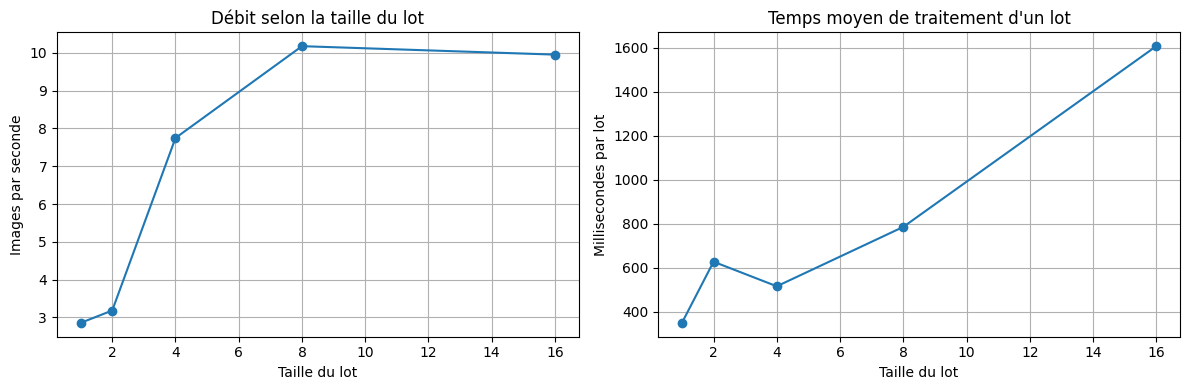

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(throughput_df["batch_size"], throughput_df["throughput_img_s"], marker="o")
axes[0].set_title("Débit selon la taille du lot")
axes[0].set_xlabel("Taille du lot")
axes[0].set_ylabel("Images par seconde")
axes[0].grid(True)

axes[1].plot(throughput_df["batch_size"], throughput_df["mean_batch_ms"], marker="o")
axes[1].set_title("Temps moyen de traitement d'un lot")
axes[1].set_xlabel("Taille du lot")
axes[1].set_ylabel("Millisecondes par lot")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 7. Mesurer la mémoire

Il faut distinguer :
- la mémoire des paramètres du modèle ;
- la mémoire des activations intermédiaires ;
- la mémoire allouée et réservée par le moteur d'exécution.

Sur GPU NVIDIA, PyTorch expose notamment le pic de mémoire allouée et réservée par son allocateur.


In [16]:
def model_parameter_size_mib(model):
    total_bytes = sum(
        parameter.numel() * parameter.element_size()
        for parameter in model.parameters()
    )
    return total_bytes / (1024 ** 2)

print(f"Taille des paramètres : {model_parameter_size_mib(model):.2f} MiB")

if device.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    test_batch = make_batch(8)
    _ = run_inference(test_batch)
    torch.cuda.synchronize()

    allocated_mib = torch.cuda.max_memory_allocated() / (1024 ** 2)
    reserved_mib = torch.cuda.max_memory_reserved() / (1024 ** 2)

    print(f"Pic de mémoire allouée : {allocated_mib:.2f} MiB")
    print(f"Pic de mémoire réservée : {reserved_mib:.2f} MiB")
else:
    print("La mesure détaillée du pic mémoire CPU nécessite un outil de profilage dédié.")

Taille des paramètres : 44.59 MiB
La mesure détaillée du pic mémoire CPU nécessite un outil de profilage dédié.


### 7.1 Pourquoi la taille du fichier ne suffit-elle pas ?

La taille des paramètres ne correspond pas à toute la mémoire nécessaire à l'exécution. Il faut également stocker les entrées, les sorties et les activations intermédiaires.

La mémoire nécessaire peut augmenter avec la résolution des images et la taille des lots. C'est une des raisons pour lesquelles la quantification sera étudiée dans la prochaine séquence.

## 8. Observer le coût du prétraitement

Une application doit généralement décoder et redimensionner les images, normaliser les pixels et convertir les données en tenseurs. Le prétraitement peut représenter une part importante du temps total, surtout lorsque le modèle est devenu rapide.


In [17]:
from PIL import Image

dummy_image = Image.new("RGB", (640, 480), color=(120, 160, 200))

def benchmark_preprocessing(image, repetitions=100):
    durations = []
    for _ in range(repetitions):
        start = time.perf_counter()
        _ = processor(images=image, return_tensors="pt")
        durations.append((time.perf_counter() - start) * 1000)

    return {
        "mean_ms": statistics.mean(durations),
        "median_ms": statistics.median(durations),
    }

preprocess_result = benchmark_preprocessing(dummy_image)
print(f"Prétraitement moyen : {preprocess_result['mean_ms']:.2f} ms")
print(f"Prétraitement médian : {preprocess_result['median_ms']:.2f} ms")

Prétraitement moyen : 4.20 ms
Prétraitement médian : 3.91 ms


### 8.1 Interpréter la chaîne complète

Le temps de réponse peut être décomposé de manière simplifiée :

$$
T_{\text{total}} =
T_{\text{réception}} +
T_{\text{prétraitement}} +
T_{\text{inférence}} +
T_{\text{post-traitement}} +
T_{\text{réponse}}
$$

Optimiser uniquement le réseau ne garantit donc pas une amélioration équivalente du temps de réponse global. En production, il faut aussi considérer les transferts réseau, la mise en file d'attente, la concurrence entre requêtes et le démarrage du service.

## 9. Construire la référence (*baseline*)

Nous rassemblons les principales mesures dans un tableau. Cette référence sera comparée aux résultats des séquences suivantes.

Une comparaison n'est valable que si le protocole est identique : même modèle, même matériel, mêmes dimensions d'entrée, mêmes tailles de lots et conditions de mesure comparables.


In [18]:
baseline = {
    "model": MODEL_ID,
    "device": str(device),
    "dtype": str(next(model.parameters()).dtype),
    "parameter_size_mib": model_parameter_size_mib(model),
    "batch1_latency_mean_ms": latency_result["mean_ms"],
    "batch1_latency_median_ms": latency_result["median_ms"],
    "preprocessing_median_ms": preprocess_result["median_ms"],
}

if not throughput_df.empty:
    baseline["batch1_throughput_img_s"] = float(
        throughput_df.loc[
            throughput_df["batch_size"] == 1, "throughput_img_s"
        ].iloc[0]
    )

baseline_df = pd.DataFrame([baseline])
baseline_df

,model,device,dtype,parameter_size_mib,batch1_latency_mean_ms,batch1_latency_median_ms,preprocessing_median_ms,batch1_throughput_img_s
0,microsoft/resnet-18,cpu,torch.float32,44.591949,360.568305,325.017938,3.906544,2.857432


### 9.1 Enregistrer les résultats

Les fichiers CSV pourront être conservés et intégrés à un suivi d'expériences.


In [19]:
baseline_df.to_csv("baseline_performance.csv", index=False)
throughput_df.to_csv("baseline_throughput.csv", index=False)

print("Fichiers enregistrés :")
print("- baseline_performance.csv")
print("- baseline_throughput.csv")

Fichiers enregistrés :
- baseline_performance.csv
- baseline_throughput.csv


## 10. Synthèse

Dans cette séquence, nous avons appris à :
- mesurer le temps d'inférence en tenant compte des spécificités du GPU ;
- utiliser un préchauffage ;
- distinguer latence et débit ;
- observer l'influence de la taille des lots ;
- mesurer la taille des paramètres et, sur CUDA, le pic mémoire ;
- séparer le coût du prétraitement de celui du réseau ;
- constituer une référence de performance.

### Les idées essentielles à retenir

1. **Mesurer avant d'optimiser.** Sans référence, impossible de démontrer un gain.
2. **Mesurer dans des conditions reproductibles.** Une comparaison doit conserver le même protocole.
3. **Ne pas confondre latence et débit.** Un système qui traite beaucoup d'images par seconde n'est pas nécessairement rapide pour une requête isolée.
4. **Ne pas regarder uniquement le modèle.** Le prétraitement, les transferts et l'infrastructure influencent aussi le temps de réponse.
5. **Relier les mesures au besoin métier.** Une application interactive et un traitement par lots n'ont pas les mêmes contraintes.

## 11. Questions de compréhension

1. Quelle est la différence entre latence et débit ?
2. Pourquoi effectuer un *warm-up* avant de mesurer les performances ?
3. Pourquoi synchroniser le GPU avant de relever le temps d'exécution ?
4. Le débit augmente-t-il lorsque la taille du lot augmente ? Est-ce systématique ?
5. Pourquoi le temps moyen par image dans un lot ne représente-t-il pas nécessairement la latence ressentie par un utilisateur ?
6. Pourquoi la taille des paramètres ne suffit-elle pas à estimer la mémoire nécessaire en production ?
7. Si le prétraitement prend plus de temps que l'inférence, quelle partie faudrait-il chercher à optimiser en priorité ?

## 12. Mise en application sur votre projet

Reprenez le modèle de vision utilisé dans votre projet.

- Chargez le modèle dans son environnement d'inférence habituel.
- Mesurez sa latence pour un lot de taille 1.
- Mesurez son débit pour plusieurs tailles de lots.
- Relevez sa taille mémoire lorsque cela est possible.
- Mesurez séparément le prétraitement si votre pipeline en comporte un.
- Consignez les résultats dans un tableau.

**Livrable attendu :** une fiche de référence présentant le modèle, le matériel utilisé, le protocole de mesure et les résultats initiaux. Cette fiche sera réutilisée pour évaluer les gains obtenus grâce aux optimisations des séquences suivantes.